<a href="https://colab.research.google.com/github/Amulya-Kanuparthi/Hurricane-Damage-Analysis-and-Image-Enhancement-Using-Satellite-Imagery/blob/main/GroupE_Kanuparthi_Damera_Phase2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hurricane Damage Analysis and Image Enhancement Using Satellite Imagery
## Phase 2 — Implementation and Preliminary Evaluation
**Group E:** Amulya Kanuparthi and Adithi Damera  


### Project objective
Explore how grayscale conversion, contrast stretching, CLAHE, spatial filtering, frequency-domain analysis, and Canny edge detection change the visibility of features in satellite images of hurricane-affected areas. Compare parameter choices and quantify contrast, gradient strength, edge density, and saturation. These image-quality measures are **not** damage-classification accuracy.

### Dataset
Kevin Mader, *Satellite Images of Hurricane Damage* (Kaggle). This notebook reads the **actual local dataset** from `~/Desktop/archive/train_another/damage` and `no_damage`. It analyzes up to **100 images per class (200 total)** by default, selected reproducibly; set `N_PER_CLASS=None` to process **all available training images** (slower). The separate validation/test directories are not used to tune parameters. The images are loaded from disk when you run the notebook in VS Code; they are not embedded.



In [ ]:
import sys
import numpy as np
import cv2
import matplotlib.pyplot as plt
print('Python:', sys.version.split()[0], '| NumPy:', np.__version__, '| OpenCV:', cv2.__version__)


Python: 3.10.9 | NumPy: 1.26.4 | OpenCV: 5.0.0


In [ ]:
from pathlib import Path
DATASET_PATH = Path.home() / 'Desktop' / 'archive'
TRAIN_PATH = DATASET_PATH / 'train_another'
N_PER_CLASS = 100  # up to 100 per class; set None to use every available training image
SEED = 6397
extensions = {'.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp'}
if not TRAIN_PATH.is_dir():
    raise FileNotFoundError(f'Training folder not found: {TRAIN_PATH}. Update DATASET_PATH to your actual folder.')

def find_images(label):
    folder = TRAIN_PATH / label
    if not folder.is_dir():
        raise FileNotFoundError(f'Missing class folder: {folder}')
    return sorted(p for p in folder.rglob('*') if p.is_file() and p.suffix.lower() in extensions)

paths_by_class = {label: find_images(label) for label in ('damage', 'no_damage')}
for label, paths in paths_by_class.items():
    print(f'{label}: {len(paths)} available images')
if not all(paths_by_class.values()):
    raise ValueError('Both class folders must contain supported image files.')

rng = np.random.default_rng(SEED)
# Balanced selection; None uses all images in each class, potentially unbalanced.
selected = []
for label, paths in paths_by_class.items():
    count = len(paths) if N_PER_CLASS is None else min(N_PER_CLASS, len(paths))
    chosen = rng.choice(len(paths), size=count, replace=False)
    selected.extend((paths[int(i)], label) for i in chosen)

images, gray, labels, filenames = [], [], [], []
for path, label in selected:
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if bgr is None:
        print('Skipping unreadable:', path)
        continue
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    images.append(rgb)
    gray.append(cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY))
    labels.append(label)
    filenames.append(str(path.relative_to(DATASET_PATH)))

if not images or not all(label in labels for label in ('damage','no_damage')):
    raise ValueError('Need readable images from both classes.')
print(f'Loaded {len(images)} images: damage={labels.count("damage")}, no_damage={labels.count("no_damage")}')
print('Image dimensions (first image):', images[0].shape)

print('Representative image indices:', [labels.index('damage'), labels.index('no_damage')])


damage: 5000 available images
no_damage: 5000 available images
Loaded 200 images: damage=100, no_damage=100
Image dimensions (first image): (128, 128, 3)
Representative image indices: [0, 100]


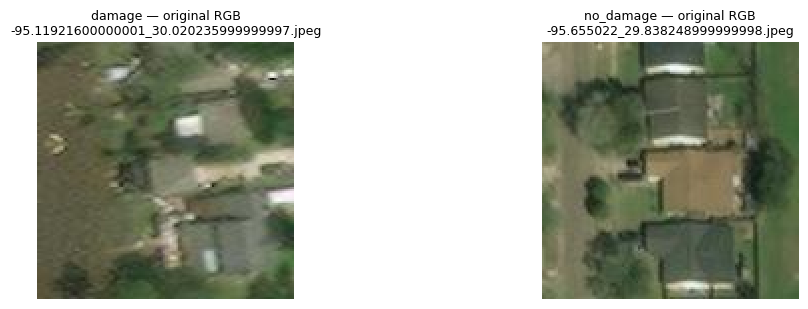

In [ ]:
def panel(arrays, titles, cols=3):
    rows=int(np.ceil(len(arrays)/cols))
    fig,axs=plt.subplots(rows,cols,figsize=(12,3.2*rows),squeeze=False)
    for ax in axs.flat: ax.axis('off')
    for ax,a,t in zip(axs.flat,arrays,titles):
        ax.imshow(a, cmap='gray' if a.ndim==2 else None, vmin=0 if a.ndim==2 else None,
                  vmax=255 if a.ndim==2 else None, interpolation='nearest')
        ax.set_title(t,fontsize=9)
    fig.tight_layout(); plt.show()

reps=[labels.index('damage'),labels.index('no_damage')]
panel([images[i] for i in reps],[labels[i]+' — original RGB\n'+Path(filenames[i]).name for i in reps],2)


## 3. Implementation: five distinct project categories
The proposal's grayscale pipeline is used to isolate luminance effects. Original RGB patches remain visible as references; grayscale conversion loses color cues such as floodwater or vegetation. No method below identifies debris or damage by itself.

### Stage 1 — Point processing: percentile contrast stretching
Map intensities between percentiles p and 100−p to 0–255 and clip values outside that interval. Compare p=0, 1, and 2; p=0 is min–max stretching. Stronger clipping can expose midtone structures but erase dark and bright detail.

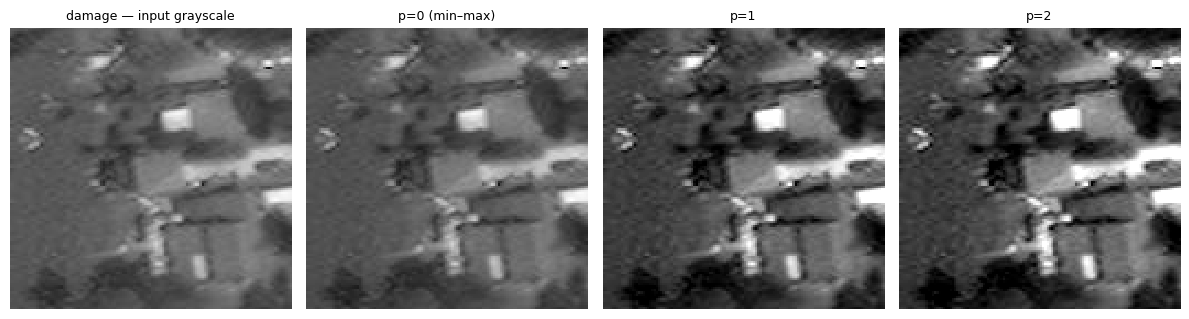

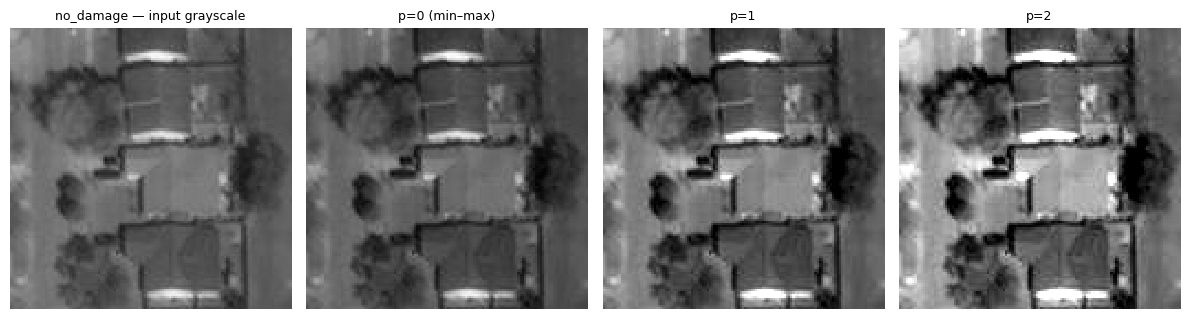

In [ ]:
def stretch(x,p=1):
    lo,hi=np.percentile(x,[p,100-p])
    if hi<=lo: return x.copy()
    return np.clip((x.astype(float)-lo)*255/(hi-lo),0,255).astype(np.uint8)
for i in reps:
    panel([gray[i]]+[stretch(gray[i],p) for p in [0,1,2]],
          [labels[i]+' — input grayscale','p=0 (min–max)','p=1','p=2'],4)


### Stage 2 — Histogram processing: CLAHE
CLAHE redistributes intensities within local tiles while limiting histogram amplification. Compare clip limits 1, 2, and 4 with an 8×8 tile grid, and compare 4×4 versus 8×8 grids at clip limit 2. Tile grid dimensions are numbers of tiles, not pixel sizes. Higher limits can exaggerate texture and create artificial contrast.

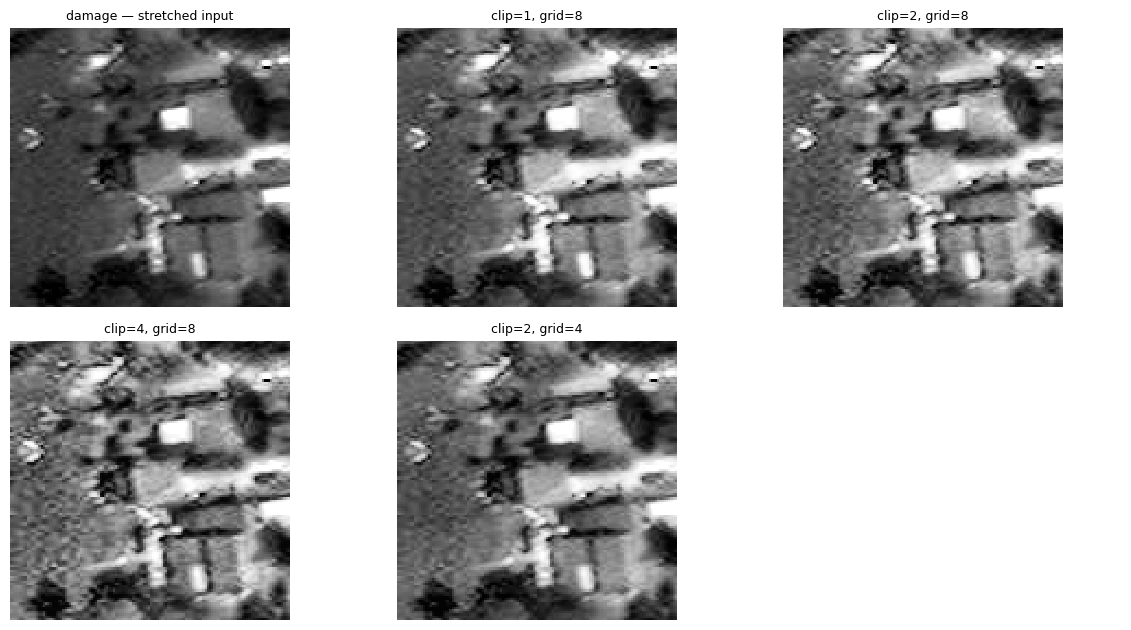

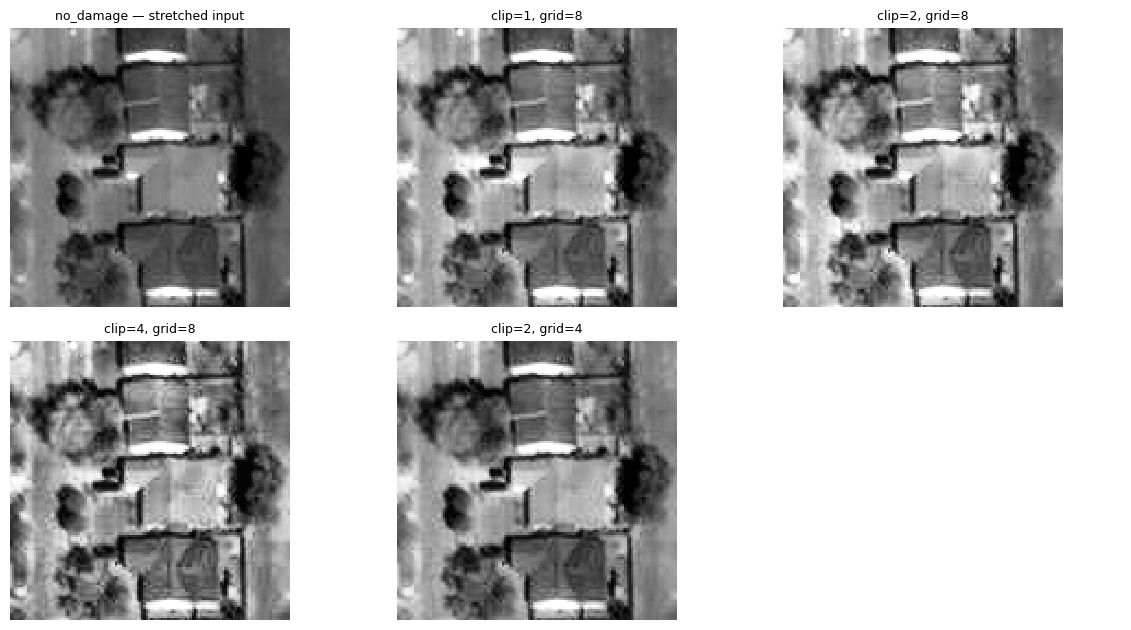

In [ ]:
def clahe(x,clip=2,grid=8):
    return cv2.createCLAHE(clipLimit=float(clip),tileGridSize=(grid,grid)).apply(x)
for i in reps:
    x=stretch(gray[i],1)
    panel([x]+[clahe(x,c) for c in [1,2,4]]+[clahe(x,2,4)],
          [labels[i]+' — stretched input','clip=1, grid=8','clip=2, grid=8','clip=4, grid=8','clip=2, grid=4'],3)


### Stage 3 — Spatial filtering: median and Laplacian sharpening
Median filtering compares no filtering (k=1) with 3×3 and 5×5 kernels. This dataset has no known clean reference or confirmed salt-and-pepper noise; smoothing is therefore a tradeoff, not proven noise removal. Laplacian sharpening uses y=clip(x−α∇²x), a 3×3 Laplacian, reflected borders, and α=0.10, 0.25, 0.50. Floating-point arithmetic prevents unsigned overflow.

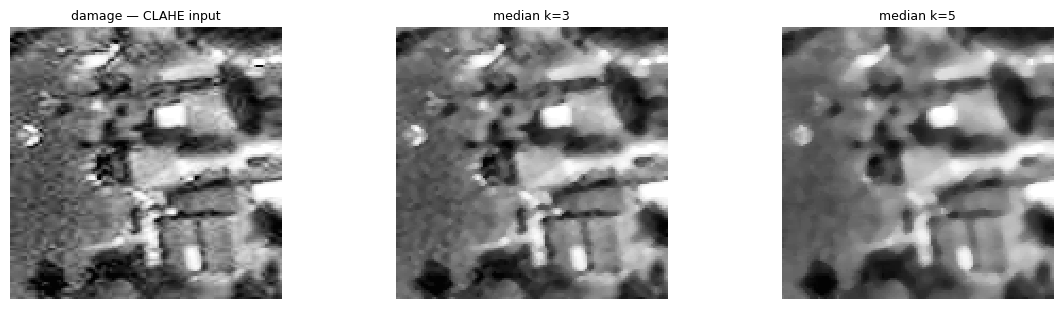

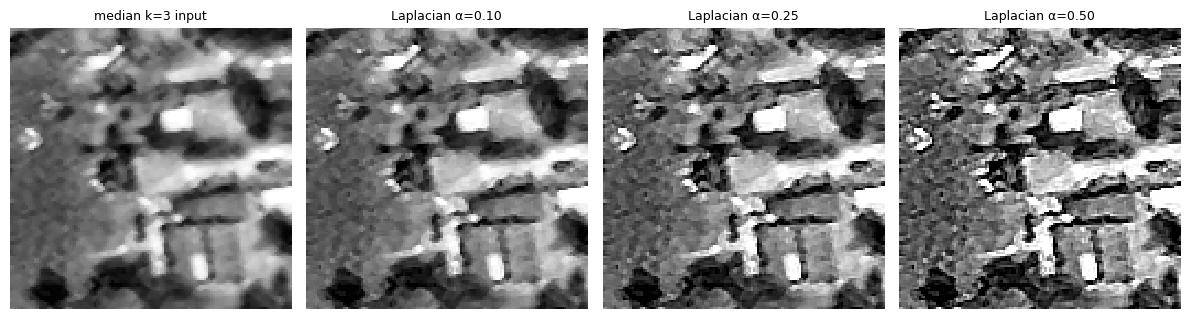

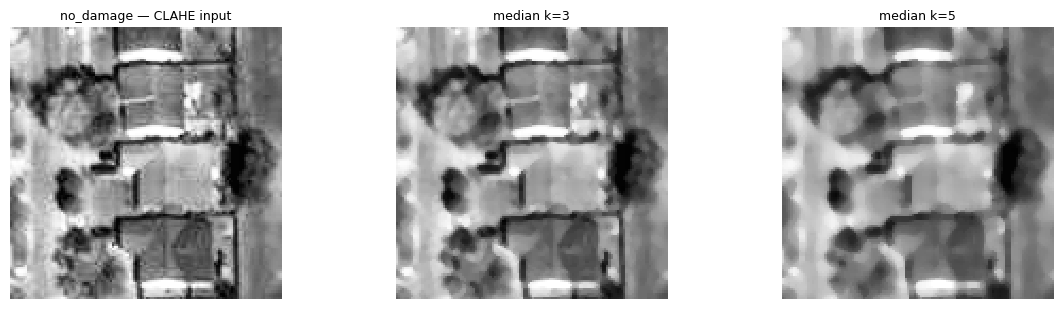

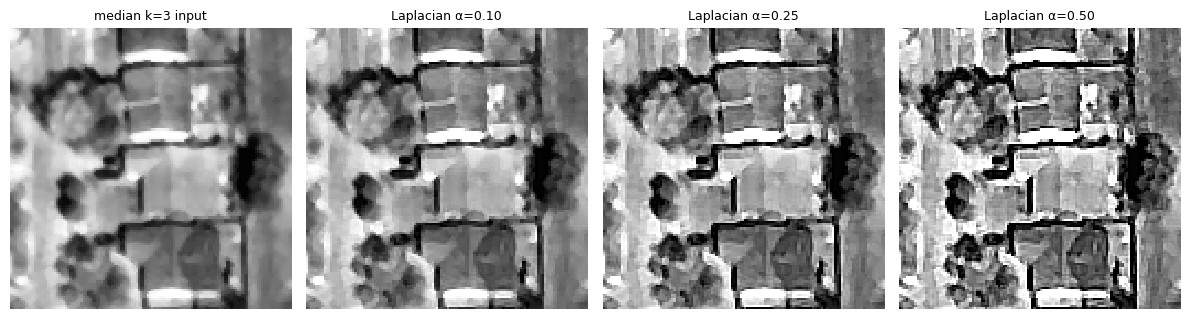

In [ ]:
def median(x,k=3): return x.copy() if k==1 else cv2.medianBlur(x,k)
def sharpen(x,alpha=.25):
    f=x.astype(np.float32)
    lap=cv2.Laplacian(f,cv2.CV_32F,ksize=3,borderType=cv2.BORDER_REFLECT_101)
    return np.clip(f-alpha*lap,0,255).astype(np.uint8)
for i in reps:
    x=clahe(stretch(gray[i],1),2,8)
    panel([x,median(x,3),median(x,5)],
          [labels[i]+' — CLAHE input','median k=3','median k=5'])
    m=median(x,3)
    panel([m]+[sharpen(m,a) for a in [.1,.25,.5]],
          ['median k=3 input','Laplacian α=0.10','Laplacian α=0.25','Laplacian α=0.50'],4)


### Stage 4 — Frequency-domain filtering: Gaussian FFT high-pass
Use H(u,v)=1−exp(−D²/(2D₀²)), where D is distance from the shifted FFT origin in frequency bins. Cutoffs D₀=5, 10, and 20 are compared. Reflect padding by 32 pixels reduces boundary wraparound; after inverse FFT, crop to the original size. The signed response has near-zero mean and is displayed around gray 128 with a fixed gain of 2. It is a detail map, not a natural-brightness image, so it will be retained as a separate analysis branch rather than passed directly into Canny.

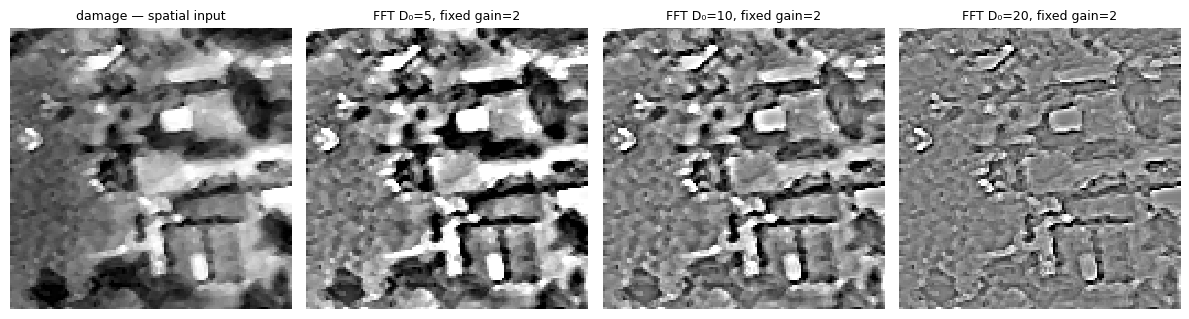

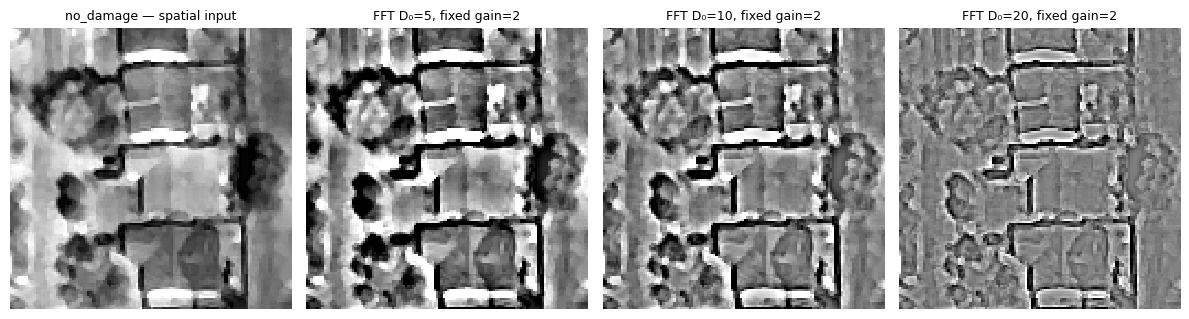

In [ ]:
def fft_highpass(x,d0=10):
    p=32; f=np.pad(x.astype(float),p,mode='reflect'); h,w=f.shape
    yy,xx=np.ogrid[:h,:w]
    d2=(yy-h//2)**2+(xx-w//2)**2
    H=1-np.exp(-d2/(2*d0*d0))
    out=np.fft.ifft2(np.fft.ifftshift(np.fft.fftshift(np.fft.fft2(f))*H)).real
    return out[p:-p,p:-p]
for i in reps:
    x=sharpen(median(clahe(stretch(gray[i],1),2),3),.1)
    panel([x]+[np.clip(128+2*fft_highpass(x,d),0,255) for d in [5,10,20]],
          [labels[i]+' — spatial input','FFT D₀=5, fixed gain=2','FFT D₀=10, fixed gain=2','FFT D₀=20, fixed gain=2'],4)


### Stage 5 — Edge detection: Canny
Apply identical 3×3 Gaussian pre-smoothing (σ=0.8) and Canny settings to the original and enhanced grayscale images. Compare threshold pairs (30,90), (50,150), and (80,200). `L2gradient=True` and aperture size 3 are fixed. Low thresholds admit weak texture edges; high thresholds may omit building boundaries. An edge map is a structural feature representation, not a damage segmentation mask.

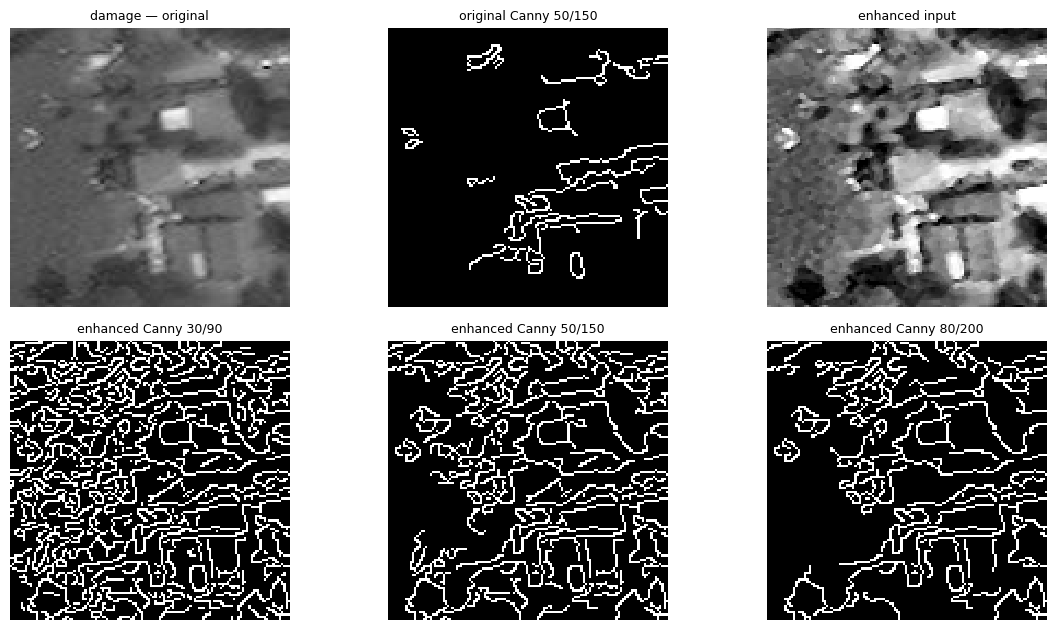

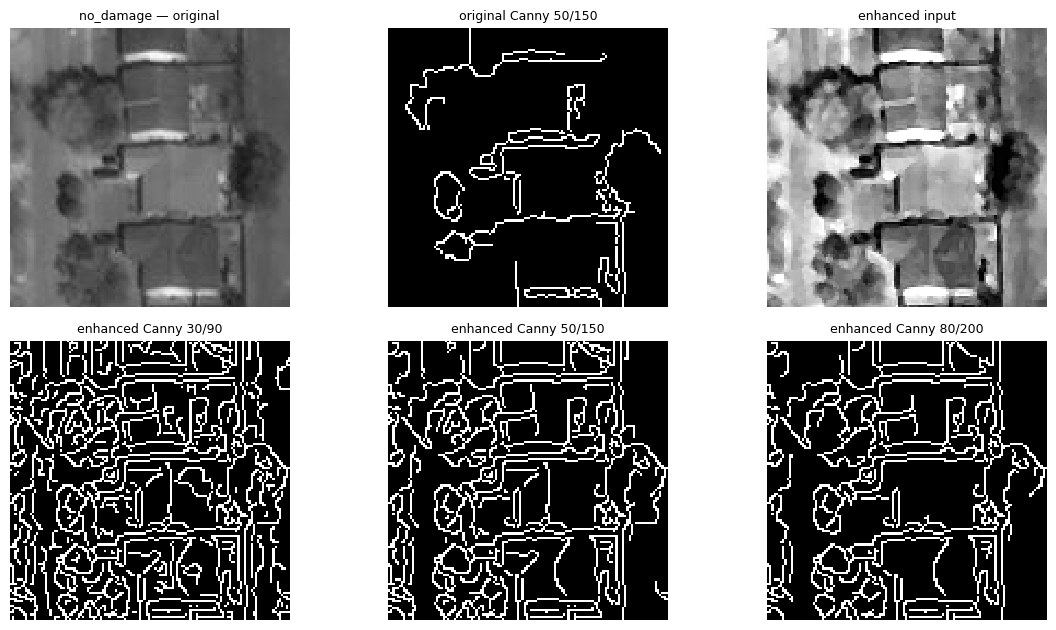

In [ ]:
def edges(x,threshold=(50,150)):
    sm=cv2.GaussianBlur(x,(3,3),.8,borderType=cv2.BORDER_REFLECT_101)
    return cv2.Canny(sm,*threshold,apertureSize=3,L2gradient=True)
def stages(x):
    s=stretch(x,1); c=clahe(s,2,8); m=median(c,3); a=sharpen(m,.1)
    return [x,s,c,m,a]
for i in reps:
    a=stages(gray[i])[-1]
    panel([gray[i],edges(gray[i]),a]+[edges(a,t) for t in [(30,90),(50,150),(80,200)]],
          [labels[i]+' — original','original Canny 50/150','enhanced input','enhanced Canny 30/90','enhanced Canny 50/150','enhanced Canny 80/200'])


## 4. Preliminary objective evaluation
Report mean intensity standard deviation (global contrast), mean Sobel gradient magnitude (edge strength), Canny edge-pixel percentage, and saturation percentage (pixels at 0 or 255). These quantify image changes; higher values are not automatically better. For median filtering, report gradient retention relative to its CLAHE input. FFT response RMS is measured in intensity units without display normalization. No PSNR/SSIM quality claim is made because a clean target is unavailable; no accuracy/F1 claim is made because no classifier or pixel-level ground truth has been evaluated.

The same twenty patches are used for parameter exploration and the selected pipeline. Tables report development-set descriptive statistics, not independent validation. One factor is varied at a time; the experiment does not exhaustively optimize parameter combinations.

All metrics below are recomputed from the actual images loaded above; they will change if the dataset or selection changes.

In [ ]:
def metrics(x):
    f=x.astype(np.float32)
    gx=cv2.Sobel(f,cv2.CV_32F,1,0,ksize=3)
    gy=cv2.Sobel(f,cv2.CV_32F,0,1,ksize=3)
    return [float(x.std()),float(np.hypot(gx,gy).mean()),100*np.mean(edges(x)>0),100*np.mean((x==0)|(x==255))]
names=['Original','Stretch p=1','CLAHE 2 / 8','Median k=3','Laplacian α=.10']
all_stages=[stages(x) for x in gray]
stage_means=[]
print('STAGE                    Contrast SD | Sobel mean | Edge % | Saturation %')
for j,n in enumerate(names):
    v=np.mean([metrics(ss[j]) for ss in all_stages],axis=0); stage_means.append(v)
    print(f'{n:25s} '+' | '.join(f'{a:8.3f}' for a in v))
print('\nCLASS / original → enhanced mean edge %, SD across images')
for label in ['damage','no_damage']:
    idx=[i for i,s in enumerate(labels) if s==label]
    for j in [0,4]:
        v=[metrics(all_stages[i][j])[2] for i in idx]
        print(label,names[j],f'{np.mean(v):.3f} ± {np.std(v,ddof=1) if len(v)>1 else 0.0:.3f}')
experiments=[]
def record(name,outs):
    v=np.mean([metrics(x) for x in outs],axis=0)
    experiments.append((name,*v)); print(f'{name:27s} '+' | '.join(f'{a:8.3f}' for a in v))
print('\nPARAMETERS                 Contrast SD | Sobel mean | Edge % | Saturation %')
for p in [0,1,2]: record(f'Stretch p={p}',[stretch(x,p) for x in gray])
ss=[stretch(x,1) for x in gray]
for c,g in [(1,8),(2,8),(4,8),(2,4)]: record(f'CLAHE clip={c}, grid={g}',[clahe(x,c,g) for x in ss])
cc=[clahe(x,2,8) for x in ss]
for k in [1,3,5]:
    oo=[median(x,k) for x in cc]; record(f'Median k={k}',oo)
    ret=np.mean([metrics(y)[1]/metrics(x)[1] for x,y in zip(cc,oo)])
    print(f'  Mean gradient retention: {100*ret:.2f}%')
mm=[median(x,3) for x in cc]
for a in [.1,.25,.5]: record(f'Laplacian alpha={a}',[sharpen(x,a) for x in mm])
aa=[sharpen(x,.1) for x in mm]
for d in [5,10,20]:
    v=[np.sqrt(np.mean(fft_highpass(x,d)**2)) for x in aa]
    print(f'FFT cutoff={d}: mean signed response RMS={np.mean(v):.3f}')
for t in [(30,90),(50,150),(80,200)]:
    v=[100*np.mean(edges(x,t)>0) for x in aa]
    print(f'Canny {t}: mean edge density={np.mean(v):.3f}%')


STAGE                    Contrast SD | Sobel mean | Edge % | Saturation %
Original                    27.683 |   47.627 |    4.938 |    0.029
Stretch p=1                 54.565 |   94.638 |   12.998 |    2.262
CLAHE 2 / 8                 61.104 |  136.870 |   19.954 |    1.172
Median k=3                  58.886 |  108.526 |   15.616 |    0.889
Laplacian α=.10             62.304 |  133.688 |   19.342 |    2.780

CLASS / original → enhanced mean edge %, SD across images
damage Original 2.525 ± 2.084
damage Laplacian α=.10 18.309 ± 4.973
no_damage Original 7.351 ± 3.025
no_damage Laplacian α=.10 20.375 ± 4.235

PARAMETERS                 Contrast SD | Sobel mean | Edge % | Saturation %
Stretch p=0                   36.139 |   61.651 |    7.530 |    0.046
Stretch p=1                   54.565 |   94.638 |   12.998 |    2.262
Stretch p=2                   60.697 |  105.972 |   14.879 |    4.399
CLAHE clip=1, grid=8          61.291 |  121.375 |   17.395 |    1.177
CLAHE clip=2, grid=8        

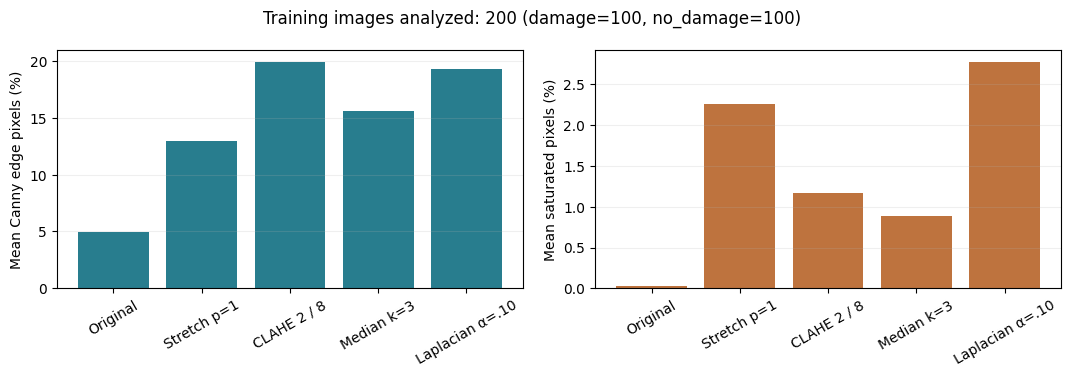

In [ ]:
fig,axs=plt.subplots(1,2,figsize=(11,3.8))
v=np.array(stage_means)
axs[0].bar(names,v[:,2],color='#287d8e'); axs[0].set_ylabel('Mean Canny edge pixels (%)')
axs[1].bar(names,v[:,3],color='#be733e'); axs[1].set_ylabel('Mean saturated pixels (%)')
for ax in axs: ax.tick_params(axis='x',rotation=30); ax.grid(axis='y',alpha=.2)
fig.suptitle(f'Training images analyzed: {len(images)} (damage={labels.count("damage")}, no_damage={labels.count("no_damage")})'); fig.tight_layout(); plt.show()


### Consolidated results: final pipeline compared with the original
The following figure shows the one representative image from each class through the entire serial pipeline. The median filter is **included provisionally** in this Phase 2 implementation (kernel 3×3); a no-median ablation is a planned Phase 3 experiment. The frequency-domain output remains a diagnostic branch rather than an input to Canny.

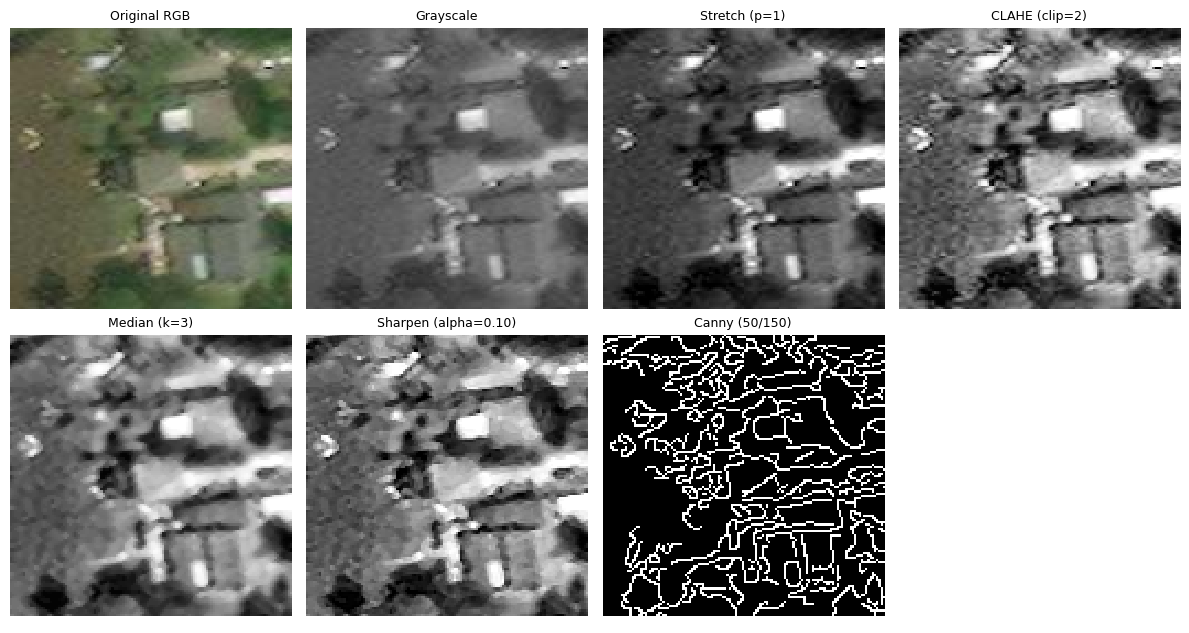

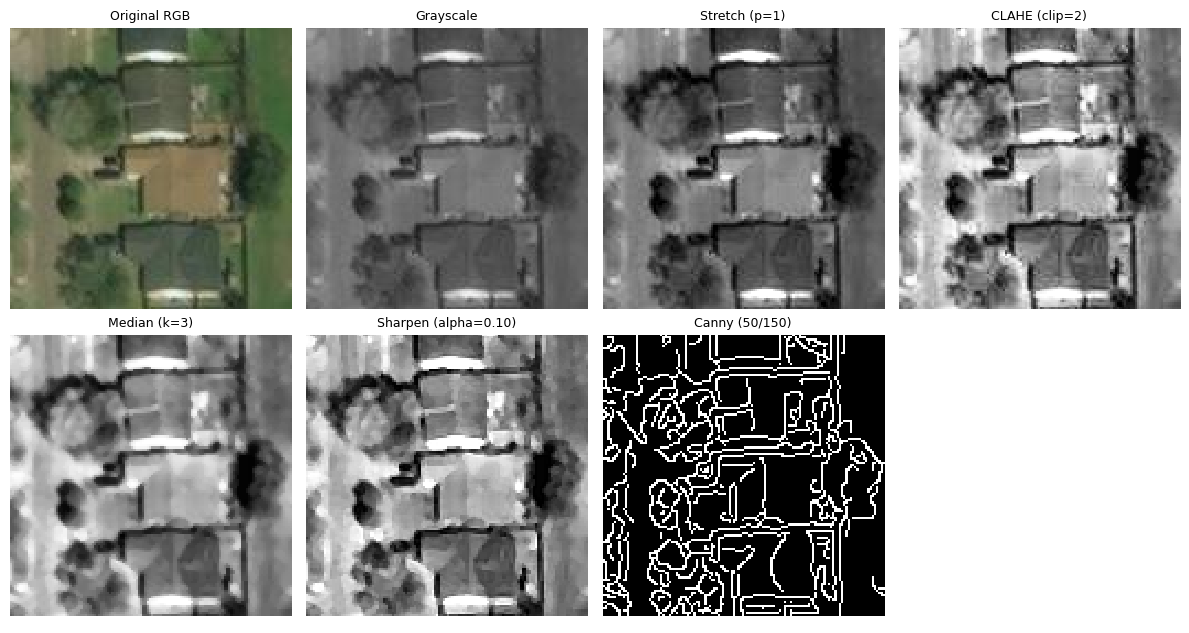

In [ ]:
for i in reps:
    original=gray[i]
    st=stages(original)
    final_edges=edges(st[-1],(50,150))
    panel([images[i],original,st[1],st[2],st[3],st[4],final_edges],
          ['Original RGB','Grayscale','Stretch (p=1)','CLAHE (clip=2)','Median (k=3)',
           'Sharpen (alpha=0.10)','Canny (50/150)'],cols=4)

### Parameter selection summary

| Technique | Settings tested | Provisional choice | Interpretation |
|---|---|---|---|
| Percentile stretch | p = 0, 1, 2 | p = 1 | Improved contrast with less clipping than p = 2 |
| CLAHE | clip = 1, 2, 4; grids 4 and 8 | clip = 2, grid = 8×8 | Moderates texture amplification |
| Median smoothing | k = 1, 3, 5 | k = 3, provisional | Retains more gradient detail than k = 5; bypass not yet tested as final pipeline |
| Laplacian sharpening | α = 0.10, 0.25, 0.50 | α = 0.10 | Limits overshoot and saturation |
| FFT high-pass | D₀ = 5, 10, 20 | D₀ = 10, diagnostic only | Isolates fine details without redefining Canny input |
| Canny | 30/90, 50/150, 80/200 | 50/150 | Compromise between weak-edge clutter and missed boundaries |

**Interpretation:** These choices are guided by the 20 development images and the measured tradeoffs below. A larger held-out sample and, ideally, manually annotated structural boundaries are needed to evaluate whether the pipeline actually improves damage-related feature extraction.

## 5. Preliminary analysis and parameter decisions
The figures and metrics above are calculated from the selected local dataset images. Use the printed numerical tables rather than assuming results from a different 20-image experiment.

- **Contrast stretching:** Percentile clipping expands the visible intensity range but can discard highlights and shadows. Compare `p=0`, `p=1`, and `p=2` using both contrast SD and saturation percentage. A higher SD is not automatically better.
- **CLAHE:** Local contrast can make boundaries clearer but may amplify vegetation texture, compression artifacts, and noise. Compare clip limits and tile grids in the table before choosing a setting.
- **Median filtering:** A 3×3 kernel may reduce isolated variation; 5×5 can erase thin structural details. Gradient retention measures smoothing, not ground-truth noise reduction. Include the `k=1` bypass as a control.
- **Laplacian sharpening:** Stronger alpha can emphasize roof outlines, but also halos and clipped pixels. Favor a conservative setting unless visual comparisons support stronger sharpening.
- **FFT high-pass:** This is a **diagnostic branch**, not a required input to Canny. Its signed response emphasizes fine spatial variation; RMS is not a measure of damage-detection accuracy.
- **Canny:** Lower thresholds produce more edge pixels, including clutter; higher thresholds can miss faint structures. Compare outputs visually for both classes. Edge density does not measure detection accuracy.

**Decision for Phase 2:** Keep percentile stretch (`p=1`), CLAHE (`clip=2`, `grid=8`), provisional median (`k=3`), mild Laplacian sharpening (`alpha=0.10`), and Canny (`50/150`) as an initial pipeline. These settings remain provisional until assessed using independent annotated structures. Do not claim that the larger image count alone establishes generalization.

**Limitations:** Image-level labels do not provide building-level damage masks. This study measures image-processing effects, not classifier accuracy. The current training selection is for development only.


## 6. Updated pipeline
Original RGB (preserved for reference) → grayscale → percentile stretch (1–99%) → CLAHE (clip=2, grid=8×8) → provisional median (k=3; bypass test pending) → Laplacian sharpening (α=.10) → Gaussian smoothing (3×3, σ=.8) → Canny (50/150) → structural feature comparison.

Parallel diagnostic branch: sharpened grayscale → reflect padding → FFT Gaussian high-pass (D₀=10) → inverse FFT and crop → signed detail map / RMS.

**Change from Phase 1:** FFT high-pass is no longer a mandatory input to Canny. Median filtering remains included in the current implementation, but a bypass comparison is planned because detail preservation matters at small patch sizes. Parameters are provisional rather than final.

## 7. Next steps before Phase 3
- Evaluate on an independent validation/test split after selecting parameters, checking duplicate coordinates and nearby-location leakage.
- Compare color-preserving luminance enhancement with grayscale processing so floodwater and vegetation cues are retained.
- Review larger crops or manually annotate a small set of building boundaries; then measure edge precision/recall with a stated tolerance rather than edge density alone.
- Test median bypass and smaller sharpening strength; investigate blur, halos, clipping, and texture-induced false edges.
- Evaluate whether structural features help classification using a simple baseline and held-out labels, if classification remains in scope.
- Optional VGG16 transfer learning remains unimplemented and is not required for this checkpoint.

## References and attribution
1. Group E, *Hurricane Damage Analysis and Image Enhancement Using Satellite Imagery*, Phase 1 proposal supplied for this assignment.
2. kmader / Kevin Mader, *Satellite Images of Hurricane Damage*, Kaggle, version 1: https://www.kaggle.com/datasets/kmader/satellite-images-of-hurricane-damage. Original images reproduced for analysis; source paths and hashes are included above.
3. Chen et al. (2018), *Benchmark Dataset for Automatic Damaged Building Detection from Post-Hurricane Remotely Sensed Imagery*: https://arxiv.org/abs/1812.05581.
4. OpenCV reference: https://docs.opencv.org/4.x/ (CLAHE, medianBlur, Laplacian, GaussianBlur, Canny).
